# Stained-Glass Crisp

**Author:** Iman Mossavat · Fontys ICT

## What creates stained-glass crisp?

This image is made from Voronoi cells. Points are first relaxed for even spacing, then each pixel is assigned to its nearest seed, colored by a recipe, and finally streaked, cracked, and bordered with rounded lead lines.

![Final stained-glass artwork](../assets/stained_glass_crisp_preview.png)


In [1]:
%matplotlib inline
import numpy as np
import matplotlib.pyplot as plt
from math_vis import seeds_relaxed, cell_colors, glass_crisp, make_cmap, finish

SEED = 4
W, H = 360, 460
N_CELLS = 160
LLOYD = 4
rng = np.random.default_rng(SEED)

## Relaxing the seeds

`seeds_relaxed` scatters points randomly, then moves each point toward the center of its Voronoi cell. This produces a more even, organic spacing than pure random placement.

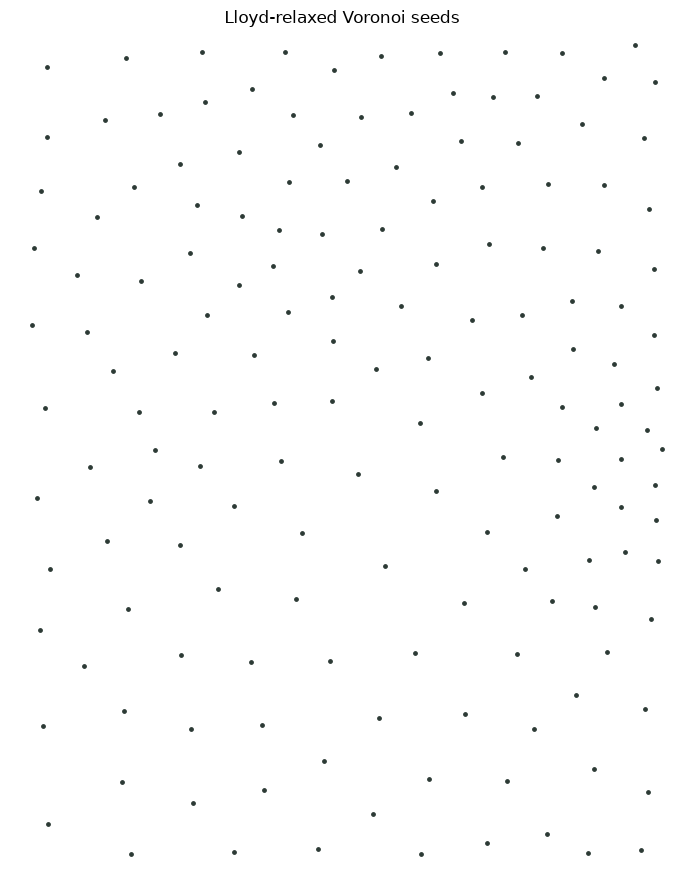

In [2]:
# 1. Generate and relax seeds
seeds = seeds_relaxed(N_CELLS, W, H, rng, iters=LLOYD)
fig, ax = plt.subplots(figsize=(7, 9))
ax.scatter(seeds[:,0], seeds[:,1], s=6, c='#2c3a35')
ax.set_xlim(0,W); ax.set_ylim(0,H); ax.set_aspect('equal'); ax.axis('off')
ax.set_title('Lloyd-relaxed Voronoi seeds')
plt.tight_layout(); plt.show()

> **Question:** What would the cells look like if you set `LLOYD=0` and skipped relaxation? Predict, then try it.

## Coloring the cells

`cell_colors` assigns a scalar value to each seed based on position and a little randomness. That scalar is then mapped through a palette to give every cell its color.

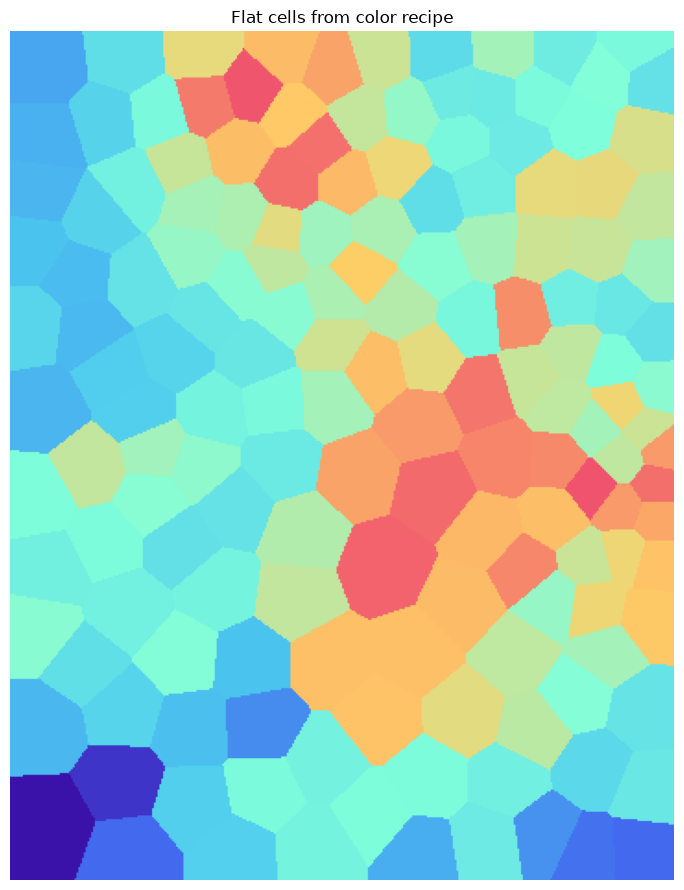

In [3]:
# 2. Assign colors to cells
t = cell_colors(seeds, W, H, rng, trend=0.5)

# visualize just the cell assignment
from scipy.spatial import cKDTree
X, Y = np.meshgrid(np.arange(W)+0.5, np.arange(H)+0.5)
P = np.column_stack([X.ravel(), Y.ravel()])
cell = cKDTree(seeds).query(P)[1]
palette = make_cmap(['#3a0ca3', '#4361ee', '#4cc9f0', '#80ffdb', '#ffd166', '#ef476f', '#d62828'])
flat = (palette(t)[cell, :3] * 255).reshape(H, W, 3).astype(np.uint8)

fig, ax = plt.subplots(figsize=(7, 9))
ax.imshow(flat, origin='lower'); ax.axis('off')
ax.set_title('Flat cells from color recipe')
plt.tight_layout(); plt.show()

> **Question:** The color recipe mixes position (`trend`) with randomness. Which do you think has more influence in the current image?

## Building the image stage by stage

`glass_crisp` adds warp, lead lines, rounded edges, streaks, cracks, and contours. Each stage is a small visual effect; together they create the illusion of old glass.

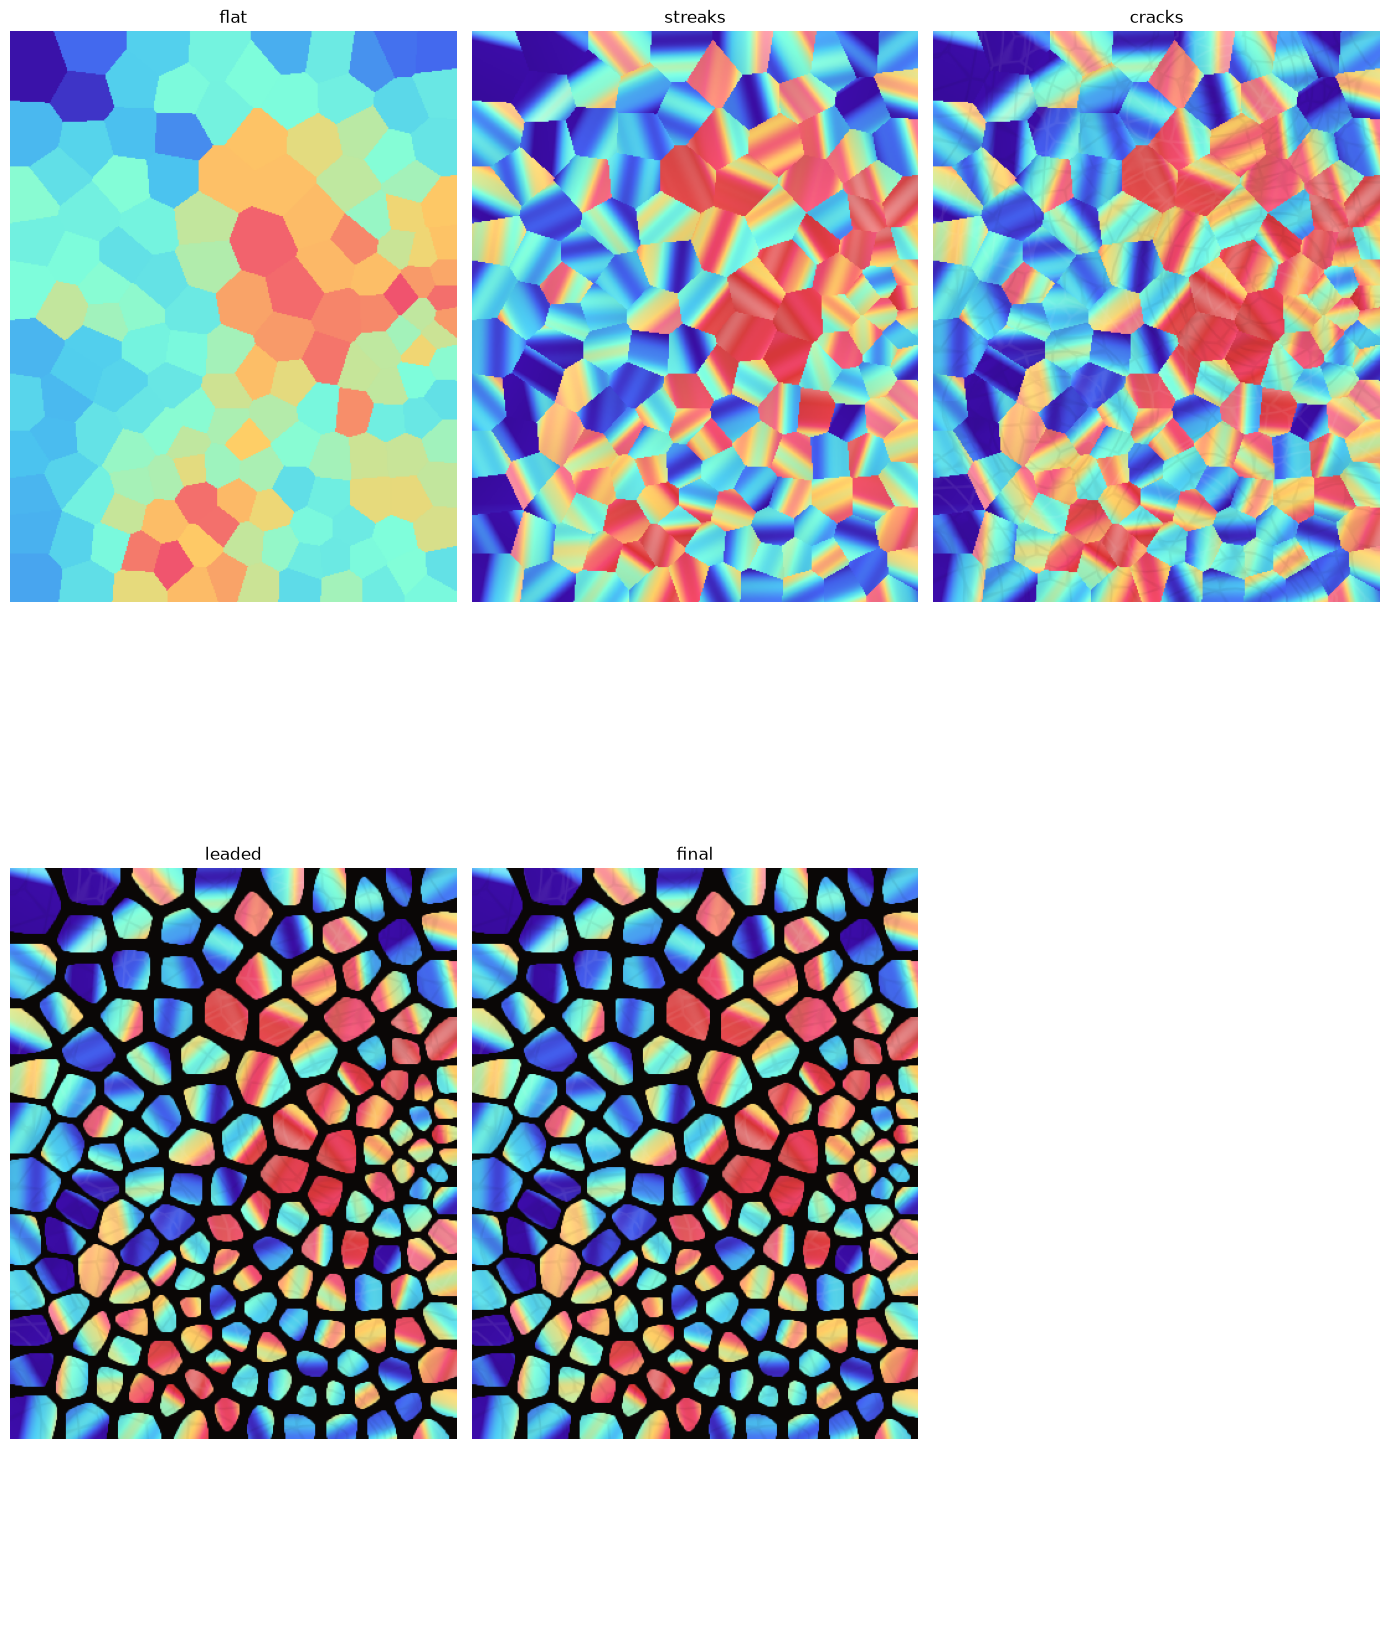

In [4]:
# 3. Build the image stage by stage
img, stages = glass_crisp(
    seeds, t, palette, W, H, rng=rng,
    warp=0.04,
    lead_px=3,
    round_px=2.5,
    streak=0.55,
    streak_light=0.45,
    crack_alpha=0.10,
    contour_alpha=0.12,
    stages=True
)

fig, axes = plt.subplots(2, 3, figsize=(14, 18))
for (name, img), ax in zip(stages.items(), axes.ravel()):
    ax.imshow(img)
    ax.set_title(name)
    ax.axis('off')
# hide any unused panels in the 2x3 grid
for ax in axes.ravel()[len(stages):]:
    ax.axis('off')
plt.tight_layout(); plt.show()

> **Question:** Which stage makes the flat cells look three-dimensional — the streaks, the rounded lead, or the cracks?

## Experiments

Try changing `N_CELLS`, `LLOYD`, `warp`, `streak`, `crack_alpha`, or the palette. Start with one change at a time and re-run from the parameter cell onward.

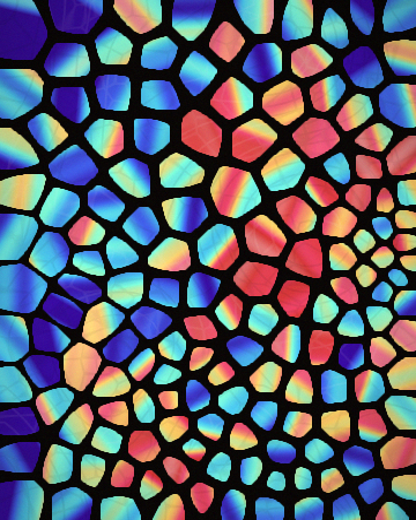

In [5]:
# 4. Final render at print resolution
final = finish(stages['final'], name='stained_glass_crisp.png', grain=2, vignette=0.35, display=False)
from IPython.display import display
from PIL import Image
preview = Image.fromarray(final).resize((416, 520))
display(preview)

## What did we learn?

- **Lloyd relaxation** makes Voronoi cells more regular without making them perfectly uniform.
- A **color recipe** based on cell position creates coherent regions.
- Small details (streaks, cracks, rounded lead) add material realism.

**Open questions:**
1. What happens if you skip Lloyd relaxation entirely?
2. How does the `warp` parameter change the geometry of the cells?

**Further experiment:** Try a palette with only warm colors, or increase `crack_alpha`.